# How Many Worlds? PCA + K-Means on UN Country Data

**Research question:** Can the world be meaningfully divided into only two groups — *developed* and *developing* countries — or does the data suggest a more complex structure?

**Dataset:** `UN.csv` — 207 countries/territories, 12 social & economic indicators (fertility, contraception, education, life expectancy, infant mortality, GDP per capita, labour-force participation, illiteracy). The values date from the late 1990s (this is the UN dataset distributed with John Fox's *car* R package), so country positions reflect that period, not today.

**Plan**
1. Prepare the data — missing values, outliers, scaling
2. PCA — what are the main dimensions separating countries?
3. PCA + K-Means — start at k = 2, then let the data choose k
4. Put countries back in — one representative country per cluster

All random processes use a fixed seed, so re-running the notebook reproduces every number.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score)

SEED = 42
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)

# Plot style: recessive grid/axes, thin marks
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
    "legend.frameon": False,
})
INK, MUTED = "#0b0b0b", "#8a8984"
BLUE, RED = "#2a78d6", "#e34948"
# Cluster colours ordered from least to most developed (CVD-validated set);
# each cluster also gets its own marker shape so colour is never the only cue.
LEVEL_COLORS = ["#e34948", "#eda100", "#1baf7a", "#2a78d6"]
LEVEL_MARKERS = ["o", "s", "^", "D"]

---
## Part 1 — Prepare the data

### 1.1 Load and explore

In [2]:
raw = pd.read_csv("UN.csv")
print(raw.shape)
raw.head()

(207, 14)


,country,region,tfr,contraception,educationMale,educationFemale,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale
0,Afghanistan,Asia,6.90,NaN,NaN,NaN,45.0,46.0,154.0,2848.0,87.5,7.2,52.800,85.00
1,Albania,Europe,2.60,NaN,NaN,NaN,68.0,74.0,32.0,863.0,NaN,NaN,NaN,NaN
2,Algeria,Africa,3.81,52.0,11.1,9.9,67.5,70.3,44.0,1531.0,76.4,7.8,26.100,51.00
3,American.Samoa,Asia,NaN,NaN,NaN,NaN,68.0,73.0,11.0,NaN,58.8,42.4,0.264,0.36
4,Andorra,Europe,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
tfr,197.0,3.53,1.76,1.19,1.95,3.07,4.98,8.0
contraception,144.0,43.43,23.71,2.00,21.00,47.00,64.00,86.0
educationMale,76.0,11.41,3.05,3.30,9.75,11.25,13.90,17.2
educationFemale,76.0,11.28,3.48,2.00,9.32,11.65,13.65,17.8
lifeMale,196.0,63.63,9.79,36.00,57.38,66.50,70.90,77.4
lifeFemale,196.0,68.39,11.04,39.10,59.60,72.15,76.43,82.9
infantMortality,201.0,43.48,38.76,2.00,12.00,30.00,66.00,169.0
GDPperCapita,197.0,6261.95,9355.66,36.00,442.00,1779.00,7272.00,42416.0
economicActivityMale,165.0,76.46,7.69,51.20,72.30,76.80,81.20,93.0
economicActivityFemale,165.0,46.79,16.81,1.90,37.00,48.40,56.40,90.6


In [4]:
raw["region"].value_counts()

region
Africa     55
Asia       50
Europe     44
America    41
Oceania    17
Name: count, dtype: int64

**Variables.** `country` is an identifier and `region` is a categorical label — neither goes into PCA/K-Means (we keep `region` aside to *interpret* clusters afterwards). That leaves 12 numeric indicators as candidates.

### 1.2 Missing values

In [5]:
num_cols = raw.select_dtypes("number").columns.tolist()
miss = (raw[num_cols].isna().mean() * 100).sort_values(ascending=False).round(1)
miss.to_frame("% missing")

,% missing
educationFemale,63.3
educationMale,63.3
contraception,30.4
illiteracyMale,22.7
illiteracyFemale,22.7
economicActivityMale,20.3
economicActivityFemale,20.3
lifeFemale,5.3
lifeMale,5.3
tfr,4.8


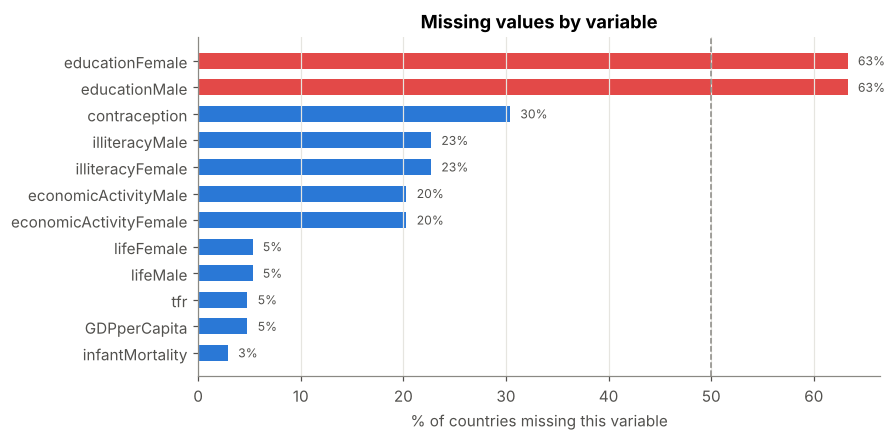

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(miss.index[::-1], miss.values[::-1], color=[RED if v > 50 else BLUE for v in miss.values[::-1]], height=0.6)
ax.axvline(50, color=MUTED, ls="--", lw=1)
ax.set_xlabel("% of countries missing this variable")
ax.set_title("Missing values by variable")
ax.grid(axis="y", visible=False)
for i, v in enumerate(miss.values[::-1]):
    ax.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=8, color="#52514e")
plt.savefig(FIG / "01_missing_by_variable.png"); plt.show()

**Decision 1 — drop `educationMale` and `educationFemale`.** They are missing for 63% of countries (131 of 207). Imputing two-thirds of a column would mean inventing most of it; and the information they carry (schooling) is largely captured by the two illiteracy variables, which are far more complete.

That leaves **10 analysis variables**. Next: how much is each *country* missing?

In [7]:
features_raw = ["tfr", "contraception", "lifeMale", "lifeFemale", "infantMortality",
                "GDPperCapita", "economicActivityMale", "economicActivityFemale",
                "illiteracyMale", "illiteracyFemale"]
n_missing = raw[features_raw].isna().sum(axis=1)
print(n_missing.value_counts().sort_index().rename("countries").to_frame().T)
raw.loc[n_missing > 4, ["country", "region"]].assign(missing=n_missing[n_missing > 4])

           0   1   2   3   4   5   6   9   10
countries  97  30  41  15   8   7   6   1   2


,country,region,missing
1,Albania,Europe,5
4,Andorra,Europe,10
5,Angola,Africa,5
6,Antigua,America,5
22,Bosnia,Europe,5
49,Dominica,America,6
51,East.Timor,Asia,6
66,Gaza.Strip,Asia,6
71,Grenada,America,5
107,Liechtenstein,Europe,6


**Decision 2 — drop countries missing more than 4 of the 10 variables (16 countries).** For these, over 40% of the profile would be imputed, so their cluster would mostly reflect our assumptions. They are mostly micro-states and territories (Andorra, Monaco, San Marino, Tuvalu, Virgin Islands…) plus a few places where data collection was disrupted (Somalia, Bosnia, Gaza Strip, Western Sahara). We keep **191 countries**.

**Decision 3 — impute the remaining gaps with the median of the country's region.** Countries in the same region tend to be more alike than the world as a whole, so the regional median is a better guess than the global one; the median (not the mean) is used because several variables are skewed. (In Session 7 we filled with the *global* median; here the regional median avoids, e.g., giving Niger the world-median illiteracy rate.) If a whole region were missing a variable we fall back to the global median (it never triggers here). We flag imputed cells so they can be checked later.

In [8]:
df = raw.loc[n_missing <= 4, ["country", "region"] + features_raw].reset_index(drop=True)
imputed_mask = df[features_raw].isna()
for col in features_raw:
    df[col] = df[col].fillna(df.groupby("region")[col].transform("median")).fillna(df[col].median())

print("Countries kept:", len(df))
print("Imputed cells:", int(imputed_mask.values.sum()), f"({imputed_mask.values.mean():.1%} of all cells)")
print("Remaining missing values:", int(df[features_raw].isna().sum().sum()))

Countries kept: 191
Imputed cells: 189 (9.9% of all cells)
Remaining missing values: 0


### 1.3 Outliers
We look at the distribution of each variable and flag values outside 1.5 × IQR.

In [9]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

out = pd.DataFrame({
    "skewness": df[features_raw].skew().round(2),
    "IQR outliers": df[features_raw].apply(iqr_outliers),
})
out

,skewness,IQR outliers
tfr,0.49,0
contraception,-0.10,0
lifeMale,-0.82,1
lifeFemale,-0.84,0
infantMortality,1.10,4
GDPperCapita,2.01,28
economicActivityMale,-0.49,11
economicActivityFemale,-0.04,21
illiteracyMale,1.30,3
illiteracyFemale,0.97,0


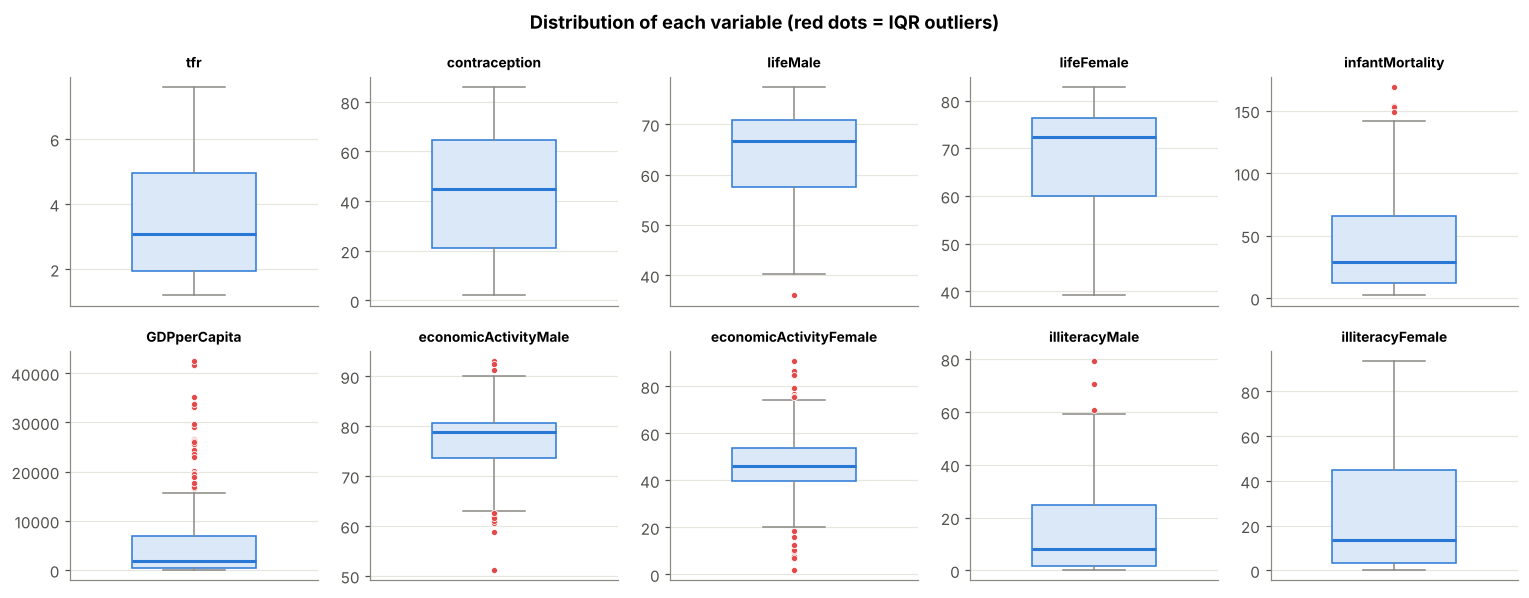

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(14, 5.5))
for ax, col in zip(axes.ravel(), features_raw):
    ax.boxplot(df[col], vert=True, widths=0.5, patch_artist=True,
               boxprops=dict(facecolor="#dbe8f8", edgecolor=BLUE),
               medianprops=dict(color=BLUE, lw=2), whiskerprops=dict(color=MUTED),
               capprops=dict(color=MUTED), flierprops=dict(marker="o", ms=4, mfc=RED, mec="white", mew=0.5))
    ax.set_title(col, fontsize=9); ax.set_xticks([])
fig.suptitle("Distribution of each variable (red dots = IQR outliers)", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "02_boxplots.png"); plt.show()

In [11]:
top_gdp = df.nlargest(8, "GDPperCapita")[["country", "GDPperCapita"]]
print(top_gdp.to_string(index=False))

    country  GDPperCapita
Switzerland       42416.0
      Japan       41718.0
 Luxembourg       35109.0
     Norway       33734.0
    Denmark       33191.0
    Germany       29632.0
    Austria       29006.0
    Belgium       26582.0


**Decision 4 — log-transform GDP per capita, keep all other values.**

* `GDPperCapita` is extremely right-skewed (skewness ≈ 2): a handful of rich countries (Switzerland, Japan, Luxembourg, Norway…) sit far above everyone else. On the raw scale, the difference between \$20,000 and \$40,000 would count as much as the difference between \$300 and \$20,300 — economically that is wrong; income gains matter proportionally. Taking `log10` fixes the skew and is also how *Factfulness* draws its income axis.
* The other "outliers" are real, meaningful observations — e.g. Gulf states with very low female labour participation, or countries with very high infant mortality. They are exactly the differences we want clusters to capture, so we **do not delete or cap them**. K-Means is sensitive to extreme points, so in Part 3 we check that the final clusters barely change if we cap every variable at its 1st/99th percentile.
* We also sanity-checked suspicious-looking values (e.g. illiteracy below 1% in former Soviet countries) — they are plausible and kept.

In [12]:
df["logGDP"] = np.log10(df["GDPperCapita"])
FEATURES = ["tfr", "contraception", "lifeMale", "lifeFemale", "infantMortality",
            "logGDP", "economicActivityMale", "economicActivityFemale",
            "illiteracyMale", "illiteracyFemale"]
print("Skewness GDP raw: %.2f  ->  log10: %.2f" % (df.GDPperCapita.skew(), df.logGDP.skew()))

Skewness GDP raw: 2.01  ->  log10: 0.03


### 1.4 Scaling

PCA and K-Means are both based on **variances and Euclidean distances**, so a variable measured in big units dominates everything. Below, without scaling, the variance of GDP per capita (in dollars²) is millions of times larger than that of fertility (in children²) — PCA on the unscaled data would just rediscover "GDP", and K-Means would cluster on GDP alone.

**Decision 5 — standardise every variable to mean 0, standard deviation 1 (`StandardScaler`).** Every indicator then has an equal chance to shape the components and the distances.

In [13]:
print("Variance of raw variables:")
print(df[features_raw].var().apply(lambda v: f"{v:,.1f}").to_string())

pca_unscaled = PCA().fit(df[features_raw])
print(f"\nPCA on UNSCALED raw data: PC1 explains {pca_unscaled.explained_variance_ratio_[0]:.1%} "
      f"and is {abs(pca_unscaled.components_[0][features_raw.index('GDPperCapita')]):.3f} GDP — it is just GDP.")

scaler = StandardScaler()
X = scaler.fit_transform(df[FEATURES])
print("\nAfter scaling: means ≈", np.round(X.mean(0), 2).max(), "| std =", np.round(X.std(0), 2)[0])

Variance of raw variables:
tfr                                2.9
contraception                    520.9
lifeMale                          94.0
lifeFemale                       119.7
infantMortality                1,457.9
GDPperCapita              79,881,113.2
economicActivityMale              52.1
economicActivityFemale           242.8
illiteracyMale                   295.9
illiteracyFemale                 666.6

PCA on UNSCALED raw data: PC1 explains 100.0% and is 1.000 GDP — it is just GDP.

After scaling: means ≈ 0.0 | std = 1.0


**Summary of preparation decisions**

| # | Decision | Why |
|---|---|---|
| 1 | Drop `educationMale`, `educationFemale` | 63% missing; information overlaps with illiteracy |
| 2 | Drop 16 countries missing > 4 of 10 variables | Their profile would be mostly imputed |
| 3 | Impute remaining gaps with regional median | Neighbours are similar; median is robust to skew |
| 4 | `log10(GDPperCapita)`; keep other outliers | Income is proportional; extreme values are real signal |
| 5 | Standardise (z-scores) | PCA/K-Means depend on scale; otherwise GDP dominates |

Final analysis matrix: **191 countries × 10 variables**.

---
## Part 2 — PCA: the structure of the data

In [14]:
pca = PCA(random_state=SEED).fit(X)
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)
pca_table = pd.DataFrame({"PC": [f"PC{i+1}" for i in range(len(evr))],
                          "eigenvalue": pca.explained_variance_.round(2),
                          "% variance": (evr * 100).round(1),
                          "cumulative %": (cum * 100).round(1)})
n90 = int(np.argmax(cum >= 0.90) + 1)
print(f"Components needed for >= 90% of the variance: {n90}  ({cum[n90-1]:.1%})")
pca_table

Components needed for >= 90% of the variance: 4  (90.8%)


,PC,eigenvalue,% variance,cumulative %
0,PC1,6.56,65.3,65.3
1,PC2,1.16,11.5,76.8
2,PC3,0.87,8.7,85.4
3,PC4,0.54,5.3,90.8
4,PC5,0.35,3.5,94.3
5,PC6,0.31,3.1,97.3
6,PC7,0.15,1.5,98.8
7,PC8,0.07,0.7,99.6
8,PC9,0.03,0.3,99.9
9,PC10,0.01,0.1,100.0


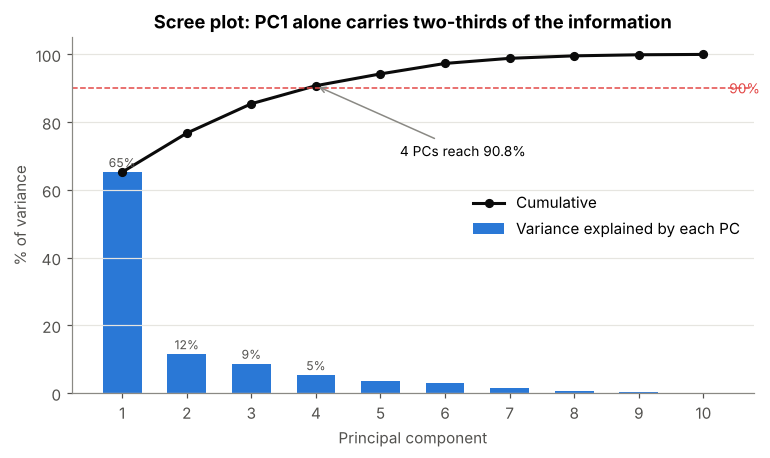

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.2))
pcs = np.arange(1, len(evr) + 1)
ax.bar(pcs, evr * 100, color=BLUE, width=0.6, label="Variance explained by each PC")
ax.plot(pcs, cum * 100, color=INK, lw=2, marker="o", ms=5, label="Cumulative")
ax.axhline(90, color=RED, ls="--", lw=1)
ax.text(10.4, 90, "90%", color=RED, va="center", fontsize=9)
ax.annotate(f"{n90} PCs reach {cum[n90-1]:.1%}", (n90, cum[n90-1] * 100), (n90 + 1.3, 70),
            arrowprops=dict(arrowstyle="->", color=MUTED), fontsize=9)
for x, v in zip(pcs[:4], evr[:4]):
    ax.text(x, v * 100 + 1.5, f"{v:.0%}", ha="center", fontsize=8, color="#52514e")
ax.set_xticks(pcs); ax.set_xlabel("Principal component"); ax.set_ylabel("% of variance")
ax.set_ylim(0, 105); ax.set_title("Scree plot: PC1 alone carries two-thirds of the information")
ax.legend(loc="center right"); ax.grid(axis="x", visible=False)
plt.savefig(FIG / "03_scree.png"); plt.show()

### Which variables drive the components?

In [16]:
loadings = pd.DataFrame(pca.components_[:4].T, index=FEATURES, columns=["PC1", "PC2", "PC3", "PC4"])
# orient PC1 so that "more developed" is positive (higher life expectancy)
if loadings.loc["lifeFemale", "PC1"] < 0:
    loadings["PC1"] *= -1
loadings.round(2)

,PC1,PC2,PC3,PC4
tfr,-0.35,-0.12,0.06,-0.21
contraception,0.33,0.02,0.08,0.41
lifeMale,0.36,-0.15,0.25,-0.02
lifeFemale,0.37,-0.09,0.17,-0.02
infantMortality,-0.37,0.05,-0.12,0.13
logGDP,0.30,-0.22,0.24,0.38
economicActivityMale,-0.19,0.21,0.87,-0.29
economicActivityFemale,0.04,0.89,-0.00,0.31
illiteracyMale,-0.34,-0.18,0.20,0.51
illiteracyFemale,-0.35,-0.19,0.15,0.44


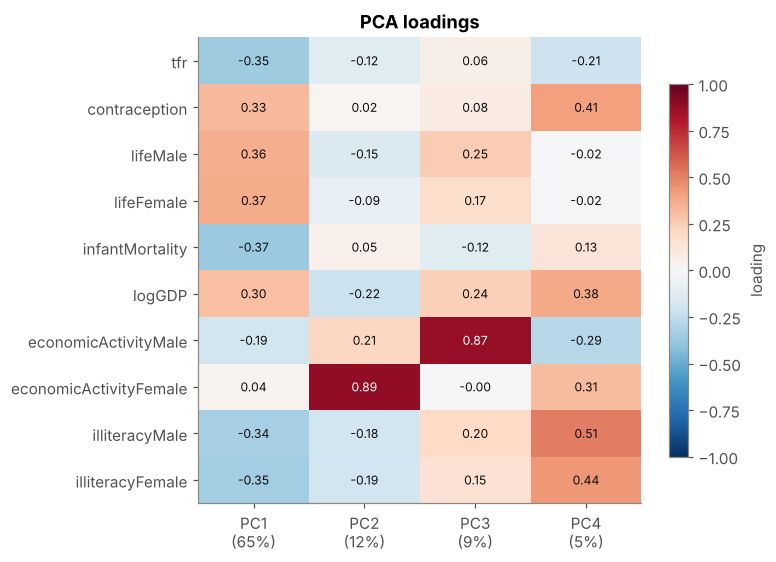

Top contributors (|loading|):
  PC1: lifeFemale (+0.37), infantMortality (-0.37), lifeMale (+0.36), tfr (-0.35)
  PC2: economicActivityFemale (+0.89), logGDP (-0.22), economicActivityMale (+0.21), illiteracyFemale (-0.19)
  PC3: economicActivityMale (+0.87), lifeMale (+0.25), logGDP (+0.24), illiteracyMale (+0.20)


In [17]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
L = loadings.values
im = ax.imshow(L, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(4)); ax.set_xticklabels([f"PC{i+1}\n({evr[i]:.0%})" for i in range(4)])
ax.set_yticks(range(len(FEATURES))); ax.set_yticklabels(FEATURES)
for i in range(L.shape[0]):
    for j in range(L.shape[1]):
        ax.text(j, i, f"{L[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(L[i, j]) > 0.55 else INK)
ax.grid(False); plt.colorbar(im, ax=ax, shrink=0.8, label="loading")
ax.set_title("PCA loadings")
plt.savefig(FIG / "04_loadings.png"); plt.show()

print("Top contributors (|loading|):")
for pc in ["PC1", "PC2", "PC3"]:
    s = loadings[pc].abs().sort_values(ascending=False).head(4)
    print(f"  {pc}: " + ", ".join(f"{k} ({loadings.loc[k, pc]:+.2f})" for k in s.index))

**Interpretation**

* **PC1 (~65%) is a "development / well-being" axis.** Nine of ten variables load almost equally on it: life expectancy, contraception and (log) GDP on the positive side; fertility, infant mortality and illiteracy on the negative side. Health, education, family size and income move *together*, so one number already orders countries from poorest/highest-mortality to richest/healthiest. The roughly equal loadings say no single indicator defines development — it is a bundle.
* **PC2 (~12%) is almost purely female economic activity** (loading ≈ 0.9). It separates countries at similar development levels by women's labour-market participation — e.g. low in North Africa and the Gulf, high in parts of sub-Saharan Africa and the former Soviet Union. This is a cultural/institutional dimension, not an income one.
* **PC3 (~9%) is mostly male economic activity**, i.e. labour-market structure (age structure, schooling years, retirement).

**Is PCA useful before clustering?** Yes:
* 10 correlated variables compress into **4 components that keep ~91% of the variance** — the remaining 6 PCs are mostly noise (each < 4%).
* Several variables are near-duplicates (lifeMale/lifeFemale, illiteracyMale/illiteracyFemale, infant mortality vs life expectancy). In raw space these double-count "health" and "literacy" in the K-Means distance; PCA removes the redundancy.
* The first 2 PCs (77%) give a faithful 2-D map to *visualise* the clusters.

We therefore cluster on the **first 4 principal-component scores**.

In [18]:
N_PC = n90
scores = pca.transform(X)
if pca.components_[0][FEATURES.index("lifeFemale")] < 0:
    scores[:, 0] *= -1   # same orientation as the loadings table
Z = scores[:, :N_PC]     # data used for clustering
for i in range(N_PC):
    df[f"PC{i+1}"] = scores[:, i]
print(Z.shape)

(191, 4)


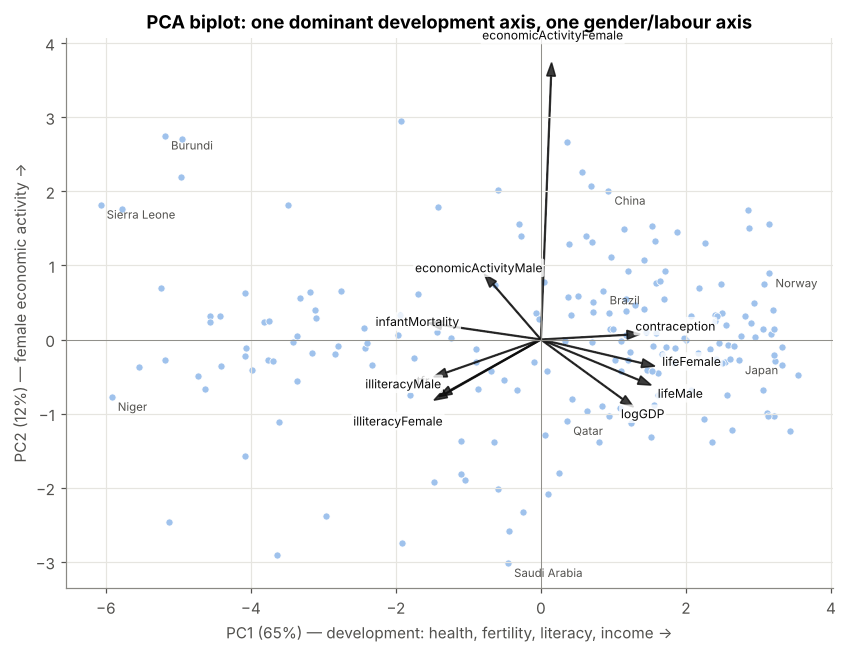

In [19]:
# Biplot: countries on PC1/PC2 + variable arrows
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.scatter(df.PC1, df.PC2, s=22, color="#9fc2ec", edgecolor="white", lw=0.5)
scale = 4.2
nudge = {"illiteracyMale": (-0.35, 0.25), "illiteracyFemale": (-0.35, -0.2), "lifeMale": (0.25, -0.05),
         "lifeFemale": (0.35, 0.1), "contraception": (0.35, 0.1)}
for f in FEATURES:
    x, y = loadings.loc[f, "PC1"] * scale, loadings.loc[f, "PC2"] * scale
    ax.arrow(0, 0, x, y, color=INK, width=0.01, head_width=0.12, length_includes_head=True, alpha=0.8)
    dx, dy = nudge.get(f, (0, 0))
    ax.text(x * 1.1 + dx, y * 1.1 + dy, f, fontsize=8, ha="center", va="center", color=INK,
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
for c in ["Norway", "Japan", "Niger", "Sierra.Leone", "Saudi.Arabia",
          "China", "Brazil", "Burundi", "Qatar"]:
    r = df[df.country == c].iloc[0]
    ax.annotate(c.replace(".", " "), (r.PC1, r.PC2), fontsize=7.5, color="#52514e",
                xytext=(4, -9), textcoords="offset points")
ax.axhline(0, color=MUTED, lw=0.6); ax.axvline(0, color=MUTED, lw=0.6)
ax.set_xlabel(f"PC1 ({evr[0]:.0%}) — development: health, fertility, literacy, income →")
ax.set_ylabel(f"PC2 ({evr[1]:.0%}) — female economic activity →")
ax.set_title("PCA biplot: one dominant development axis, one gender/labour axis")
plt.savefig(FIG / "05_biplot.png"); plt.show()

Notice the **shape** of the cloud: countries form a *continuous band* along PC1 rather than two separated blobs. There is a denser group at the right (rich + healthy) and a long tail to the left, but most countries sit **in the middle** — exactly Rosling's "most people live in the middle" point.

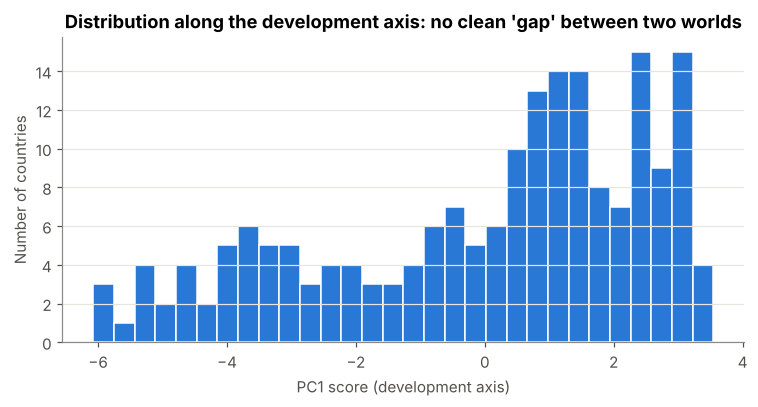

In [20]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(df.PC1, bins=30, color=BLUE, edgecolor="white")
ax.set_xlabel("PC1 score (development axis)"); ax.set_ylabel("Number of countries")
ax.set_title("Distribution along the development axis: no clean 'gap' between two worlds")
ax.grid(axis="x", visible=False)
plt.savefig(FIG / "06_pc1_hist.png"); plt.show()

---
## Part 3 — PCA + Clustering: how many worlds?

### 3.1 The traditional view: k = 2

In [21]:
def fit_km(k, data=Z):
    return KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(data)

def order_labels(labels):
    """Relabel clusters 1..k from least to most developed (mean PC1)."""
    means = pd.Series(df.PC1.values).groupby(labels).mean().sort_values()
    mapping = {old: new for new, old in enumerate(means.index, start=1)}
    return np.array([mapping[l] for l in labels])

km2 = fit_km(2)
df["k2"] = order_labels(km2.labels_)
print("Cluster sizes:", df.k2.value_counts().sort_index().to_dict())
print(f"Silhouette (k=2): {silhouette_score(Z, df.k2):.3f}")

Cluster sizes: {1: 58, 2: 133}
Silhouette (k=2): 0.493


In [22]:
profile_cols = ["tfr", "contraception", "lifeFemale", "infantMortality", "GDPperCapita",
                "economicActivityFemale", "illiteracyFemale"]
k2_profile = df.groupby("k2")[profile_cols].median().round(1)
k2_profile.insert(0, "n", df.k2.value_counts().sort_index())
k2_profile

,n,tfr,contraception,lifeFemale,infantMortality,GDPperCapita,economicActivityFemale,illiteracyFemale
k2,,,,,,,,
1,58,5.4,18.0,53.7,86.0,380.5,43.6,57.6
2,133,2.3,56.0,75.3,17.0,3183.0,47.8,6.1


In [23]:
# How heterogeneous is the big "developed" cluster?
big = df[df.k2 == 2]
print("Inside k=2 cluster 2 ('developed', n=%d):" % len(big))
for col in ["GDPperCapita", "infantMortality", "tfr", "lifeFemale", "illiteracyFemale"]:
    lo, hi = big.loc[big[col].idxmin()], big.loc[big[col].idxmax()]
    print(f"  {col:17s} from {lo[col]:>8.1f} ({lo.country}) to {hi[col]:>8.1f} ({hi.country})")
print("\nSome members:", ", ".join(big.sample(15, random_state=1).country))
print("\nk=2 cluster 1 by region:", df[df.k2 == 1].region.value_counts().to_dict())

Inside k=2 cluster 2 ('developed', n=133):
  GDPperCapita      from    122.0 (Tajikistan) to  42416.0 (Switzerland)
  infantMortality   from      2.0 (Northern.Mariana.Islands) to     78.0 (Myanmar)
  tfr               from      1.2 (Italy) to      7.2 (Oman)
  lifeFemale        from     61.8 (Myanmar) to     82.9 (France)
  illiteracyFemale  from      0.2 (Estonia) to     51.0 (Algeria)

Some members: Mexico, France, Israel, Austria, French.Guiana, Trinidad.and.Tobago, Japan, Canada, Tunisia, Tonga, Luxembourg, Sweden, Venezuela, Malaysia, Jamaica

k=2 cluster 1 by region: {'Africa': 44, 'Asia': 11, 'America': 2, 'Oceania': 1}


**What k = 2 actually finds.** The split is **58 vs 133** — not "rich West vs rest". Cluster 1 is the high-fertility, high-mortality group (mostly sub-Saharan Africa plus Afghanistan, Pakistan, India, Bangladesh, Nepal, Haiti, Yemen). Cluster 2 lumps together **everyone else**: Norway with Indonesia, Japan with Bolivia, Switzerland with Tajikistan — GDP per capita from \$122 to \$42,416 (a 350× range), infant mortality from 2 to 78 per 1,000, fertility from 1.2 to 7.2 children. Calling all of these "developed" is clearly not meaningful; the 2-group split hides the large middle of the world.

### 3.2 Testing k = 2 … 10
We use five pieces of evidence:
* **Elbow rule** — within-cluster sum of squares (inertia); we also locate the elbow objectively (point of maximum distance from the line joining the first and last points).
* **Silhouette score** — how well separated clusters are (−1 to 1, higher is better).
* **Calinski-Harabasz** (higher better) and **Davies-Bouldin** (lower better).
* **R² = between-cluster SS / total SS** — the share of the data's structure captured by the clusters.
* **Bootstrap stability** — refit K-Means on 100 bootstrap resamples; the mean Adjusted Rand Index (ARI) against the full-data solution shows how reproducible the clusters are.

In [24]:
K = range(2, 11)
total_ss = ((Z - Z.mean(0)) ** 2).sum()
rows = []
rng = np.random.default_rng(SEED)
boot_idx = [rng.choice(len(Z), len(Z), replace=True) for _ in range(100)]
for k in K:
    km = fit_km(k)
    stab = np.mean([adjusted_rand_score(km.labels_,
                     KMeans(n_clusters=k, n_init=10, random_state=b).fit(Z[idx]).predict(Z))
                    for b, idx in enumerate(boot_idx)])
    rows.append(dict(k=k, inertia=km.inertia_, R2=1 - km.inertia_ / total_ss,
                     silhouette=silhouette_score(Z, km.labels_),
                     calinski_harabasz=calinski_harabasz_score(Z, km.labels_),
                     davies_bouldin=davies_bouldin_score(Z, km.labels_),
                     stability_ARI=stab,
                     smallest_cluster=np.bincount(km.labels_).min()))
metrics = pd.DataFrame(rows).set_index("k")

# Objective elbow: max distance from the chord between first and last inertia points
x = np.array(list(K), float); y = metrics.inertia.values
xn, yn = (x - x.min()) / (x.max() - x.min()), (y - y.min()) / (y.max() - y.min())
dist = np.abs(yn - (1 - xn)) / np.sqrt(2)  # chord from (0,1) to (1,0)
ELBOW_K = int(x[np.argmax(dist)])
metrics["elbow_distance"] = dist
print("Elbow (max-distance method):", ELBOW_K, "| distance at k=4: %.3f, k=5: %.3f" % (dist[2], dist[3]))
metrics.round(3)

Elbow (max-distance method): 5 | distance at k=4: 0.219, k=5: 0.223


,inertia,R2,silhouette,calinski_harabasz,davies_bouldin,stability_ARI,smallest_cluster,elbow_distance
k,,,,,,,,
2,775.945,0.552,0.493,233.297,0.774,0.950,58,0.000
3,592.119,0.658,0.324,181.237,1.127,0.791,51,0.172
4,497.019,0.713,0.288,155.104,1.188,0.744,31,0.219
5,431.803,0.751,0.280,140.204,1.218,0.700,27,0.223
6,386.710,0.777,0.254,128.884,1.218,0.589,27,0.199
7,346.658,0.800,0.272,122.707,1.137,0.641,20,0.167
8,316.238,0.818,0.274,117.184,1.145,0.653,8,0.122
9,295.882,0.829,0.276,110.556,1.128,0.641,7,0.062
10,277.574,0.840,0.268,105.505,1.137,0.621,6,0.000


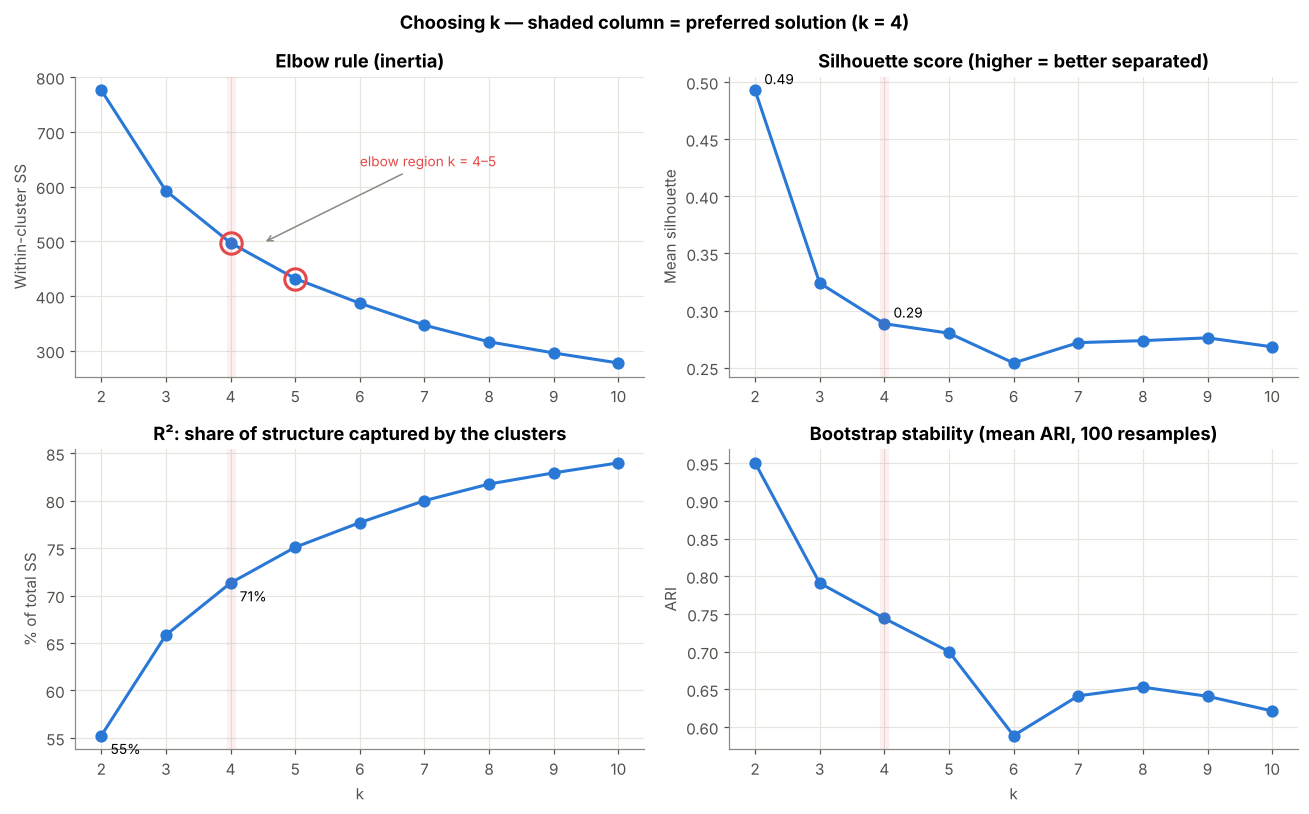

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))

ax = axes[0, 0]
ax.plot(metrics.index, metrics.inertia, color=BLUE, lw=2, marker="o", ms=7)
for kk in (4, 5):
    ax.plot(kk, metrics.inertia[kk], marker="o", ms=14, mfc="none", mec=RED, mew=2)
ax.annotate("elbow region k = 4–5", (4.5, metrics.inertia[4]), (6, metrics.inertia[4] + 140),
            arrowprops=dict(arrowstyle="->", color=MUTED), color=RED, fontsize=9)
ax.set_title("Elbow rule (inertia)"); ax.set_ylabel("Within-cluster SS")

ax = axes[0, 1]
ax.plot(metrics.index, metrics.silhouette, color=BLUE, lw=2, marker="o", ms=7)
ax.set_title("Silhouette score (higher = better separated)"); ax.set_ylabel("Mean silhouette")
for k in [2, 4]:
    ax.annotate(f"{metrics.silhouette[k]:.2f}", (k, metrics.silhouette[k]), (6, 4),
                textcoords="offset points", fontsize=9)

ax = axes[1, 0]
ax.plot(metrics.index, metrics.R2 * 100, color=BLUE, lw=2, marker="o", ms=7)
ax.set_title("R²: share of structure captured by the clusters"); ax.set_ylabel("% of total SS")
for k in [2, 4]:
    ax.annotate(f"{metrics.R2[k]:.0%}", (k, metrics.R2[k] * 100), (6, -12), textcoords="offset points", fontsize=9)
ax.set_xlabel("k")

ax = axes[1, 1]
ax.plot(metrics.index, metrics.stability_ARI, color=BLUE, lw=2, marker="o", ms=7)
ax.set_title("Bootstrap stability (mean ARI, 100 resamples)"); ax.set_ylabel("ARI"); ax.set_xlabel("k")

for a in axes.ravel():
    a.set_xticks(list(K)); a.axvline(4, color=RED, lw=6, alpha=0.08)
fig.suptitle("Choosing k — shaded column = preferred solution (k = 4)", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "07_choosing_k.png"); plt.show()

### 3.3 Silhouette profiles and PCA view: k = 2 vs k = 4

k=2: share of countries with silhouette < 0.1 (borderline): 4%
k=4: share of countries with silhouette < 0.1 (borderline): 13%


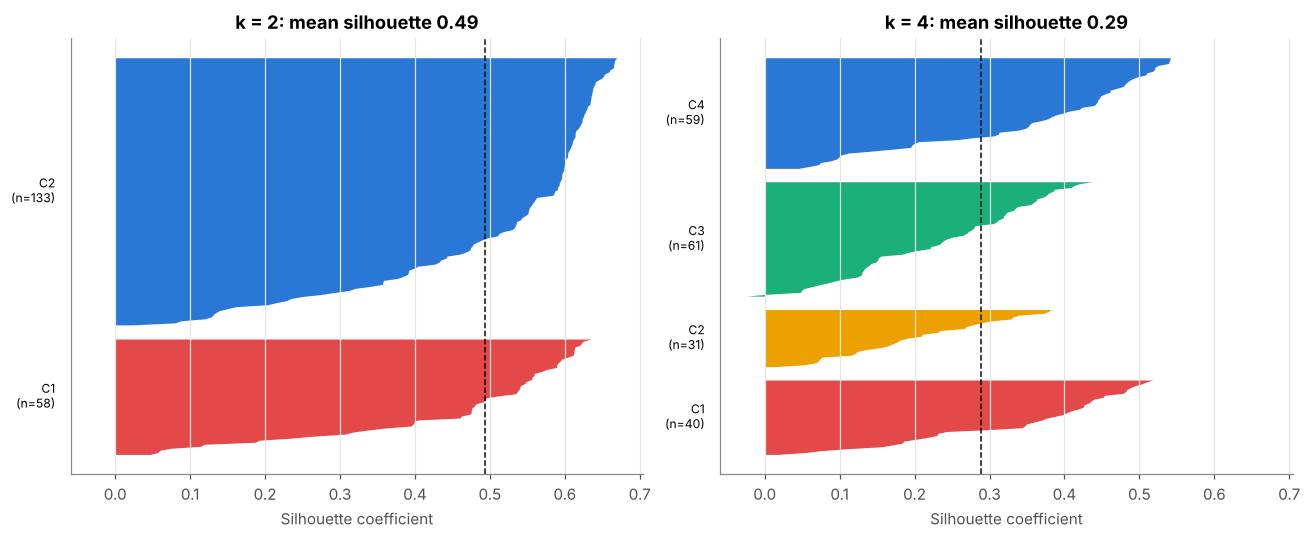

In [26]:
km4 = fit_km(4)
df["k4"] = order_labels(km4.labels_)
km3 = fit_km(3); df["k3"] = order_labels(km3.labels_)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)
for ax, col, k in [(axes[0], "k2", 2), (axes[1], "k4", 4)]:
    sil = silhouette_samples(Z, df[col]); y0 = 0
    cols = [RED, BLUE] if k == 2 else LEVEL_COLORS
    for c in range(1, k + 1):
        s = np.sort(sil[df[col] == c]); n = len(s)
        ax.fill_betweenx(np.arange(y0, y0 + n), 0, s, color=cols[c - 1], lw=0)
        ax.text(-0.08, y0 + n / 2, f"C{c}\n(n={n})", fontsize=8, ha="right", va="center")
        y0 += n + 6
    ax.axvline(sil.mean(), color=INK, ls="--", lw=1)
    ax.set_title(f"k = {k}: mean silhouette {sil.mean():.2f}")
    ax.set_yticks([]); ax.set_xlabel("Silhouette coefficient"); ax.grid(axis="y", visible=False)
    print(f"k={k}: share of countries with silhouette < 0.1 (borderline): {(sil < 0.1).mean():.0%}")
plt.tight_layout(); plt.savefig(FIG / "08_silhouette_profiles.png"); plt.show()

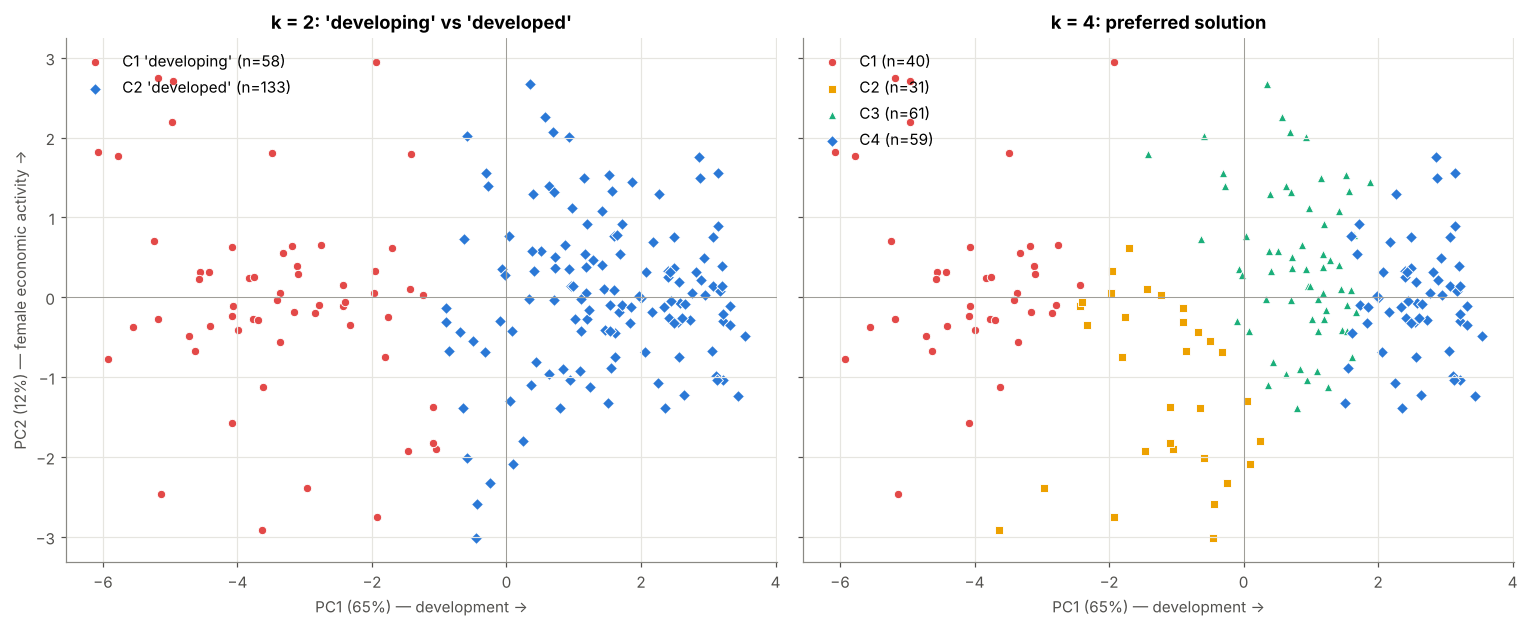

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), sharey=True)
names2 = {1: "C1 'developing'", 2: "C2 'developed'"}
for c, col, m in [(1, RED, "o"), (2, BLUE, "D")]:
    s = df[df.k2 == c]
    axes[0].scatter(s.PC1, s.PC2, s=30, color=col, marker=m, edgecolor="white", lw=0.6, label=f"{names2[c]} (n={len(s)})")
axes[0].set_title("k = 2: 'developing' vs 'developed'")

LEVEL_NAMES = {1: "C1", 2: "C2", 3: "C3", 4: "C4"}
for c in range(1, 5):
    s = df[df.k4 == c]
    axes[1].scatter(s.PC1, s.PC2, s=30, color=LEVEL_COLORS[c - 1], marker=LEVEL_MARKERS[c - 1],
                    edgecolor="white", lw=0.6, label=f"{LEVEL_NAMES[c]} (n={len(s)})")
axes[1].set_title("k = 4: preferred solution")
for ax in axes:
    ax.axhline(0, color=MUTED, lw=0.5); ax.axvline(0, color=MUTED, lw=0.5)
    ax.set_xlabel(f"PC1 ({evr[0]:.0%}) — development →"); ax.legend(loc="upper left")
axes[0].set_ylabel(f"PC2 ({evr[1]:.0%}) — female economic activity →")
plt.tight_layout(); plt.savefig(FIG / "09_pca_k2_vs_k4.png"); plt.show()

In [28]:
print("How the k=2 clusters split into the k=4 clusters:")
pd.crosstab(df.k2.map({1: "k2: C1", 2: "k2: C2"}), df.k4.map(lambda c: f"k4: C{c}"))

How the k=2 clusters split into the k=4 clusters:


k4,k4: C1,k4: C2,k4: C3,k4: C4
k2,,,,
k2: C1,40,17,1,0
k2: C2,0,14,60,59


### 3.4 Which k do we prefer?

| Evidence | What it says |
|---|---|
| **Elbow rule** | Inertia falls steeply up to k = 4–5 and flattens afterwards. The max-distance elbow detector gives k = 5, but k = 4 is virtually tied (distance 0.219 vs 0.223) — the elbow is the **k = 4–5 region**. |
| **Silhouette** | Highest at **k = 2** (0.49), then 0.32 (k = 3) and 0.29 (k = 4–5). Silhouette rewards the *single biggest gap* — the high-mortality tail on the left of PC1 — not a meaningful two-world division (see 3.1). |
| **Calinski-Harabasz / Davies-Bouldin** | Both also favour k = 2 and then change smoothly — the same "biggest gap" effect, with no competing peak. |
| **R² (structure captured)** | **55% at k = 2 vs 71% at k = 4**; the gains shrink afterwards (75% at k = 5, 78% at k = 6). |
| **Stability** | k = 2 is extremely stable (ARI 0.95); k = 3–4 remain reasonably stable (0.79 / 0.74); from k = 5 it keeps dropping (0.70 → 0.59 at k = 6), so finer splits are not reliable. |
| **Interpretability** | k = 4 gives an ordered sequence of development levels, each with a distinct, explainable profile (Part 4). |

**Our choice: k = 4.** Being honest about the evidence: separation metrics (silhouette, CH, DB) favour k = 2. But that solution is lopsided and lumps Norway with Tajikistan — it separates a *tail*, not two worlds. The data are better described as a *continuum* along PC1; on a continuum every cut is somewhat arbitrary, so we choose the k that captures most structure while staying stable and interpretable. k = 4 sits in the elbow region, explains 71% of the variance (vs 55%), is clearly more stable than k ≥ 5, and its groups make sense. k = 3 is a reasonable runner-up.

### 3.5 Cross-check with hierarchical clustering (Ward, as in Session 7)
A Ward dendrogram on the same 4 PC scores shows where the natural cuts are, without fixing k in advance.

Largest merge heights (top of tree): [43.3 17.9 13.3 12.2 11.3  8.8]
Gap between successive merges: [25.4  4.6  1.1  0.9  2.5]


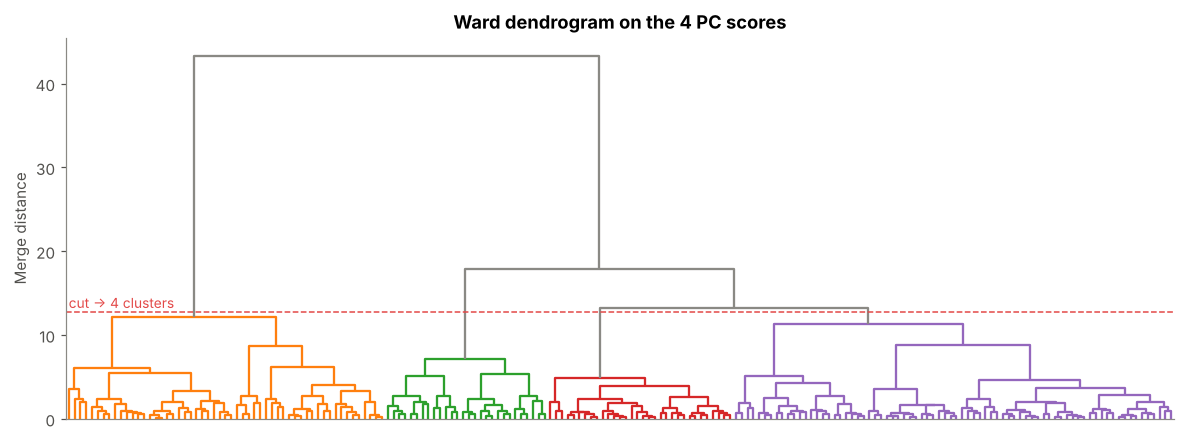

Agreement Ward(2) vs K-Means(2): ARI = 0.85
Agreement Ward(4) vs K-Means(4): ARI = 0.47


col_0,Ward W1,Ward W2,Ward W3,Ward W4
k4,,,,
K-Means C1,40,0,0,0
K-Means C2,13,18,0,0
K-Means C3,2,10,49,0
K-Means C4,0,0,27,32


In [29]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
link = linkage(Z, method="ward", metric="euclidean")
heights = link[::-1, 2][:6]
print("Largest merge heights (top of tree):", np.round(heights, 1))
print("Gap between successive merges:", np.round(-np.diff(heights), 1))

fig, ax = plt.subplots(figsize=(13, 4.5))
cut4 = (link[-4, 2] + link[-3, 2]) / 2
dendrogram(link, no_labels=True, color_threshold=cut4, above_threshold_color=MUTED, ax=ax)
ax.axhline(cut4, color=RED, ls="--", lw=1); ax.text(5, cut4 + 0.5, "cut → 4 clusters", color=RED, fontsize=9)
ax.set_title("Ward dendrogram on the 4 PC scores"); ax.set_ylabel("Merge distance"); ax.grid(False)
plt.savefig(FIG / "12_ward_dendrogram.png"); plt.show()

ward4 = fcluster(link, 4, criterion="maxclust")
print(f"Agreement Ward(2) vs K-Means(2): ARI = {adjusted_rand_score(df.k2, fcluster(link, 2, criterion='maxclust')):.2f}")
print(f"Agreement Ward(4) vs K-Means(4): ARI = {adjusted_rand_score(df.k4, ward4):.2f}")
ward_order = pd.Series(df.PC1.values).groupby(ward4).mean().rank().astype(int)
pd.crosstab(df.k4.map(lambda c: f"K-Means C{c}"), pd.Series(ward4).map(lambda w: f"Ward W{ward_order[w]}").values)

**What the dendrogram says.** The tallest merge (43.3) dwarfs all others, so Ward also finds the k = 2 split first — almost the same one as K-Means (ARI 0.85): the high-mortality tail vs. the rest. Below that, merges happen at similar heights (17.9, 13.3, 12.2, 11.3): there is **no second natural cut**, which is the signature of a continuum. Ward's 4 groups are still ordered along the development axis, but it draws the boundaries in different places (ARI 0.47 with K-Means): it splits the rich world into a core and a "near-rich" group and merges more of C1/C2. Both methods agree on the substance — an ordered gradient with several levels — but exactly where the lines fall depends on the method. That is a useful caveat for the presentation.

In [30]:
# Robustness checks for k = 4
ari_full = adjusted_rand_score(df.k4, order_labels(KMeans(4, n_init=50, random_state=SEED).fit(X).labels_))
Xw = StandardScaler().fit_transform(df[FEATURES].clip(df[FEATURES].quantile(.01), df[FEATURES].quantile(.99), axis=1))
Zw = PCA(N_PC).fit_transform(Xw)
ari_wins = adjusted_rand_score(df.k4, KMeans(4, n_init=50, random_state=SEED).fit(Zw).labels_)
heavy = imputed_mask.sum(axis=1) >= 3
ari_noimp = adjusted_rand_score(df.k4[~heavy],
    KMeans(4, n_init=50, random_state=SEED).fit(PCA(N_PC).fit_transform(StandardScaler().fit_transform(df.loc[~heavy, FEATURES]))).labels_)
print(f"ARI k=4: PCA-4 space vs all 10 scaled variables  : {ari_full:.2f}")
print(f"ARI k=4: original vs outliers capped at 1st/99th pct: {ari_wins:.2f}")
print(f"ARI k=4: original vs excluding {heavy.sum()} countries with >=3 imputed values: {ari_noimp:.2f}")

ARI k=4: PCA-4 space vs all 10 scaled variables  : 0.97
ARI k=4: original vs outliers capped at 1st/99th pct: 1.00
ARI k=4: original vs excluding 23 countries with >=3 imputed values: 0.87


Within K-Means the k = 4 partition is robust to our preparation choices: clustering on all 10 scaled variables instead of 4 PCs (ARI 0.97), capping outliers (1.00) or dropping the 23 most-imputed countries (0.87) gives almost the same groups.

---
## Part 4 — Put countries back into the analysis
### 4.1 Cluster profiles (medians, original units)

In [31]:
show = ["tfr", "contraception", "lifeMale", "lifeFemale", "infantMortality", "GDPperCapita",
        "economicActivityMale", "economicActivityFemale", "illiteracyMale", "illiteracyFemale"]
prof = df.groupby("k4")[show].median().round(1)
prof.insert(0, "n", df.k4.value_counts().sort_index())
prof["GDP $/day"] = (prof.GDPperCapita / 365).round(1)
prof

,n,tfr,contraception,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale,GDP $/day
k4,,,,,,,,,,,,
1,40,5.7,18.0,48.8,52.0,100.0,286.5,79.2,43.6,41.0,65.4,0.8
2,31,4.8,33.0,62.9,63.9,56.0,1265.0,78.8,33.0,22.0,37.7,3.5
3,61,2.8,45.0,67.3,73.0,25.0,1860.0,79.0,48.5,6.2,9.6,5.1
4,59,1.8,70.5,73.1,79.2,8.0,11854.0,71.5,51.0,1.5,3.1,32.5


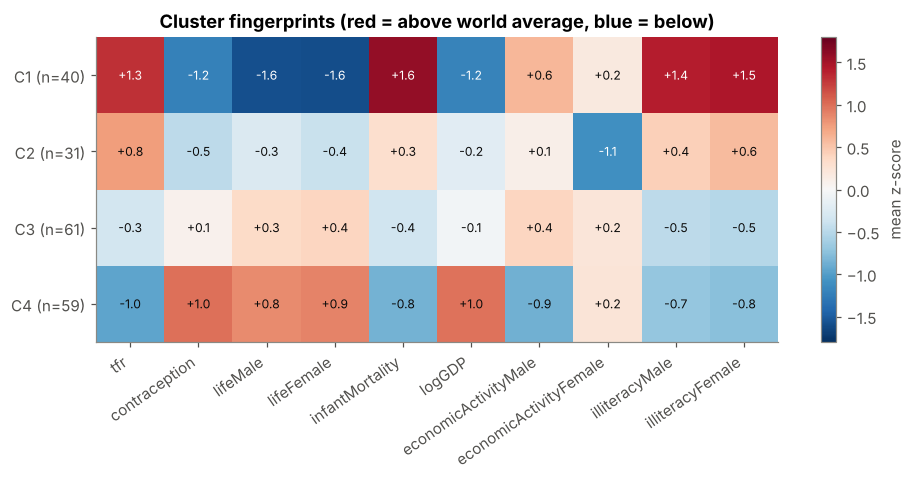

In [32]:
zprof = pd.DataFrame(X, columns=FEATURES).groupby(df.k4).mean()
fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(zprof.values, cmap="RdBu_r", vmin=-1.8, vmax=1.8, aspect="auto")
ax.set_xticks(range(len(FEATURES))); ax.set_xticklabels(FEATURES, rotation=35, ha="right")
ax.set_yticks(range(4)); ax.set_yticklabels([f"C{c} (n={(df.k4 == c).sum()})" for c in range(1, 5)])
for i in range(4):
    for j in range(len(FEATURES)):
        v = zprof.values[i, j]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 1.1 else INK)
ax.grid(False); plt.colorbar(im, ax=ax, label="mean z-score")
ax.set_title("Cluster fingerprints (red = above world average, blue = below)")
plt.savefig(FIG / "10_cluster_fingerprints.png"); plt.show()

In [33]:
print("Region composition of each cluster:")
pd.crosstab(df.k4.map(lambda c: f"C{c}"), df.region, margins=True)

Region composition of each cluster:


region,Africa,America,Asia,Europe,Oceania,All
k4,,,,,,
C1,33,1,6,0,0,40
C2,15,3,11,0,2,31
C3,3,16,25,6,11,61
C4,1,17,6,32,3,59
All,52,37,48,38,16,191


In [34]:
for c in range(1, 5):
    print(f"C{c} ({(df.k4 == c).sum()}): " + ", ".join(df[df.k4 == c].sort_values("PC1").country.str.replace(".", " ", regex=False)))
    print()

C1 (40): Sierra Leone, Niger, Burkina Faso, Mali, Ethiopia, Guinea, Burundi, Afghanistan, Malawi, Mozambique, Liberia, Chad, Uganda, Guinea Bissau, Rwanda, Gambia, Senegal, Ivory Coast, Benin, Bhutan, Mauritania, Eritrea, Djibouti, Togo, Nepal, Sudan, Central African Rep, Laos, Haiti, Nigeria, Zambia, Equatorial Guinea, Sao Tome, Dem Rep of the Congo, Tanzania, Comoros, Madagascar, Bangladesh, Congo, Cambodia

C2 (31): Yemen, Pakistan, Cameroon, Ghana, Gabon, Lesotho, Kenya, Iraq, India, Botswana, Zimbabwe, Guatemala, Papua New Guinea, Namibia, Swaziland, Morocco, Egypt, Cape Verde, Myanmar, Nicaragua, Libya, Maldives, Oman, Honduras, Saudi Arabia, Algeria, Marshall Islands, Iran, Micronesia, Jordan, Tunisia

C3 (61): Vanuatu, Bolivia, Kiribati, Turkmenistan, Tajikistan, Syria, Mongolia, South Africa, Indonesia, El Salvador, Samoa, Solomon Islands, Qatar, Philippines, Kyrgyzstan, Guyana, Paraguay, Azerbaijan, Viet Nam, Moldova, Belize, Northern Mariana Islands, Uzbekistan, Dominican Re

### 4.2 Choosing a representative country per cluster
A representative should be **typical** of its cluster, so we rank countries by their distance to their cluster centroid (in the 4-PC space) and choose a well-known country in the closest third of its cluster: **Nigeria** (12th closest of 40), **India** (2nd of 31), **Mexico** (18th of 61) and **Portugal** (5th of 59).

In [35]:
centroids = pd.DataFrame(Z).groupby(df.k4).mean()
df["dist_to_centroid"] = [np.linalg.norm(Z[i] - centroids.loc[c].values) for i, c in enumerate(df.k4)]
df["rank_in_cluster"] = df.groupby("k4").dist_to_centroid.rank().astype(int)
for c in range(1, 5):
    top = df[df.k4 == c].nsmallest(8, "dist_to_centroid")
    print(f"C{c}: " + ", ".join(f"{r.country} ({r.dist_to_centroid:.2f})" for r in top.itertuples()))

C1: Bhutan (0.46), Togo (0.55), Djibouti (0.75), Mauritania (0.79), Laos (0.85), Haiti (0.93), Rwanda (0.99), Guinea.Bissau (1.01)
C2: Libya (1.00), India (1.11), Nicaragua (1.24), Papua.New.Guinea (1.28), Myanmar (1.28), Botswana (1.36), Egypt (1.38), Lesotho (1.44)
C3: Ecuador (0.23), Korea.Dem.Peoples.Rep (0.24), Lebanon (0.33), Seychelles (0.34), Saint.Lucia (0.34), Saint.Kitts (0.57), St.Vincent (0.66), Guyana (0.70)
C4: Netherlands.Antilles (0.18), Czech.Republic (0.46), Guadeloupe (0.50), Martinique (0.53), Portugal (0.60), Cuba (0.60), Korea.Republic.of (0.60), Slovakia (0.75)


In [36]:
REPS = {1: "Nigeria", 2: "India", 3: "Mexico", 4: "Portugal"}
REP_LABELS = {1: "C1 · Nigeria", 2: "C2 · India", 3: "C3 · Mexico", 4: "C4 · Portugal"}
rep_table = df[df.country.isin(REPS.values())].set_index("country").loc[list(REPS.values())]
rep_table[["region", "k4", "rank_in_cluster", "dist_to_centroid"] + show].round(2).T

country,Nigeria,India,Mexico,Portugal
region,Africa,Asia,America,Europe
k4,1,2,3,4
rank_in_cluster,12,2,18,5
dist_to_centroid,1.27,1.11,1.02,0.6
tfr,5.97,3.07,2.75,1.48
contraception,6.0,41.0,53.0,66.0
lifeMale,50.8,62.1,69.5,71.8
lifeFemale,54.0,62.7,75.5,78.9
infantMortality,77.0,72.0,31.0,8.0
GDPperCapita,587.0,365.0,2700.0,10428.0


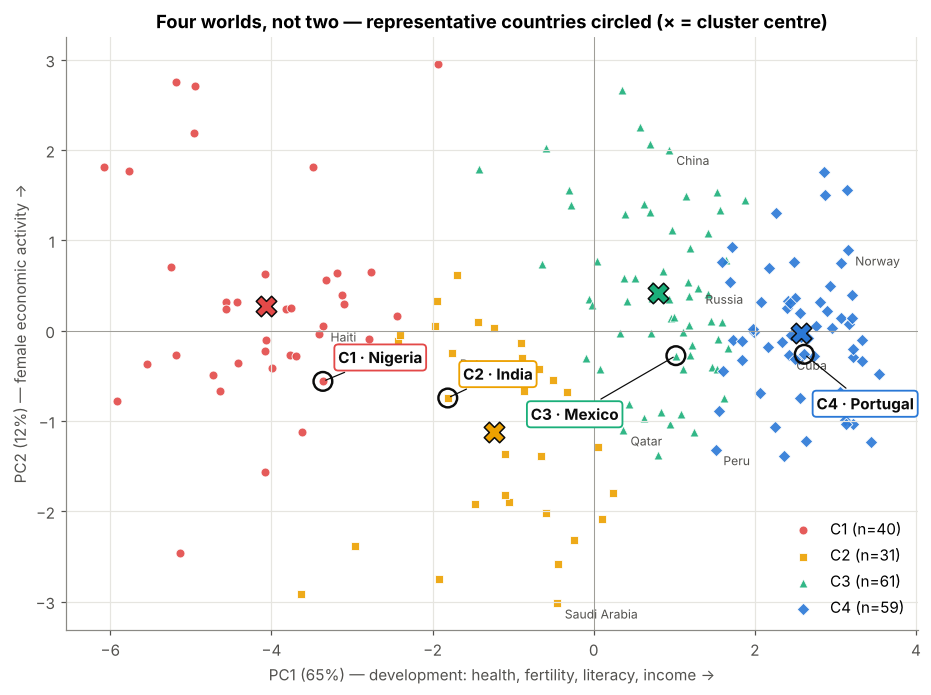

In [37]:
fig, ax = plt.subplots(figsize=(10, 7))
for c in range(1, 5):
    s = df[df.k4 == c]
    ax.scatter(s.PC1, s.PC2, s=34, color=LEVEL_COLORS[c - 1], marker=LEVEL_MARKERS[c - 1],
               edgecolor="white", lw=0.6, alpha=0.9, label=f"C{c} (n={len(s)})")
    cx, cy = s.PC1.mean(), s.PC2.mean()
    ax.scatter(cx, cy, s=180, marker="X", color=LEVEL_COLORS[c - 1], edgecolor=INK, lw=1, zorder=4)
    r = df[df.country == REPS[c]].iloc[0]
    ax.scatter(r.PC1, r.PC2, s=150, facecolor="none", edgecolor=INK, lw=1.6, zorder=5)
    off = {1: (10, 12), 2: (10, 12), 3: (-95, -42), 4: (8, -36)}[c]
    ax.annotate(REP_LABELS[c], (r.PC1, r.PC2), off, textcoords="offset points", arrowprops=dict(arrowstyle="-", color=INK, lw=0.8), fontsize=10, fontweight="bold", color=INK,
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=LEVEL_COLORS[c - 1], lw=1.2), zorder=6)
for name in ["Saudi.Arabia", "Botswana", "Cuba", "Qatar", "China", "Peru", "Russia", "Norway", "Haiti"]:
    r = df[df.country == name].iloc[0]
    ax.annotate(name.replace(".", " "), (r.PC1, r.PC2), (5, -10), textcoords="offset points", fontsize=8, color="#52514e")
ax.axhline(0, color=MUTED, lw=0.5); ax.axvline(0, color=MUTED, lw=0.5)
ax.set_xlabel(f"PC1 ({evr[0]:.0%}) — development: health, fertility, literacy, income →")
ax.set_ylabel(f"PC2 ({evr[1]:.0%}) — female economic activity →")
ax.set_title("Four worlds, not two — representative countries circled (× = cluster centre)")
ax.legend(loc="lower right")
plt.savefig(FIG / "11_four_worlds_representatives.png"); plt.show()

### 4.3 Interpreting the clusters through one country each

> Medians below are the cluster medians from the table in 4.1; country values from the table in 4.2. Data are from the late 1990s.

**C1 — Nigeria: high fertility, high mortality, very low income (≈ *Factfulness* Level 1).**
*Why here?* Nigeria had ~6 children per woman, only 6% contraceptive use, infant mortality of 77 per 1,000, life expectancy of 51/54 years and about half of women illiterate, on roughly \$1.60 a day — the C1 profile. *Similar to the others?* Yes — C1 is mostly sub-Saharan Africa (Niger, Mali, Chad, Uganda, Ethiopia…). *What distinguishes it:* the far negative end of PC1 on every health and fertility variable; median income under \$1 a day; median infant mortality 100. *Surprising:* **Haiti, Afghanistan, Nepal, Bangladesh, Laos, Cambodia and Bhutan** sit with West Africa. The group is defined by living conditions, not by continent.

**C2 — India: the start of the transition, with low female participation (≈ Level 2).**
*Why here?* India is the 2nd most typical C2 country: fertility ~3 and falling, but infant mortality still high (72), life expectancy in the low 60s, 62% female illiteracy and low female economic activity (34%). *Similar to the others?* Yes — Pakistan, Egypt, Morocco, Yemen, Myanmar, Kenya, Ghana. *What distinguishes it:* it sits between C1 and C3 on PC1 and has the most negative PC2 — women's low labour-force participation and literacy are its signature. *Surprising:* **Saudi Arabia and Oman** are here despite ~10× India's income — their fertility (5.9 in Saudi Arabia), female illiteracy and female participation (7%!) look like C2, not like Europe. **Botswana, Namibia, Lesotho, Zimbabwe** are here too: middling incomes but life expectancy pulled down by AIDS (Botswana: 52 years for women). Income and health can tell different stories.

**C3 — Mexico: the big middle (≈ Level 3).**
*Why here?* Mexico (fertility 2.75, infant mortality 31, female life expectancy 75.5, \$2,700 GDP per capita, 13% female illiteracy) is a typical member of the largest cluster. *Similar to the others?* Yes in profile, but C3 is the most geographically diverse group: Latin America (Colombia, Ecuador, Brazil), East and South-East Asia (China, Indonesia, Thailand, Philippines) and the former Soviet Union (Russia, Ukraine, Kazakhstan). *What distinguishes it:* fertility near replacement and decent literacy, but infant mortality still 3× the rich world and roughly 1/6 of its income. *Surprising:* **Qatar, Kuwait and the UAE** (incomes like Europe's) share a cluster with **China** (\$582 GDP per capita) — similar health and fertility, very different wealth. **Russia** is here, not with Europe, because of 1990s mortality, and **Lithuania** is here while Latvia and Estonia are in C4 — a sign it sits on the boundary.

**C4 — Portugal: low fertility, long lives, high income (≈ Level 4).**
*Why here?* Portugal (fertility 1.5, infant mortality 8, female life expectancy 79, \$10,400 GDP per capita) is among the most central C4 members. *Similar to the others?* Yes — Western Europe, North America, Japan, Australia, plus Central/Eastern Europe (Czech Republic, Poland, Hungary). *What distinguishes it:* the far positive end of PC1 on every variable. *Surprising:* **Cuba** (6th most typical member, with only ~\$2,000 GDP per capita) is here because its health and fertility indicators match rich countries; Costa Rica, Uruguay and Jamaica follow the same pattern. **Peru** is the C4 member furthest from the centre — a boundary case that could easily be C3. C4 describes *how people live*, not only GDP.

**The overall picture:** the four clusters form an ordered sequence along PC1 — the same progression Rosling describes with his four income levels — with PC2 (women's participation in the workforce) splitting the middle into two different kinds of transition.

---
## Conclusions — answers to the six questions

**1. Can the world be divided meaningfully into only two clusters?** A 2-cluster solution *exists* and is the best-separated (silhouette 0.49), but it is not "developed vs developing". It separates 58 high-mortality, high-fertility countries from 133 others and puts Norway, Tajikistan and Bolivia in the same "developed" group. **Statistically possible, not meaningful.**

**2. How many clusters does the data suggest?** The elbow lies in the **k = 4–5** region; R² gains shrink after 4; stability drops after 4. Silhouette, CH and DB favour k = 2 because they reward the single largest gap in what is otherwise a continuum. Weighing everything, we prefer **k = 4** (k = 3 runner-up).

**3. Structure captured by 2 vs 4 clusters:** 55% vs 71% of the total variance (between-cluster share, in the 4-PC space).

**4. Does the evidence support *Factfulness*?** **Largely yes.** The data are a continuum with most countries in the middle, and the four K-Means clusters line up with Rosling's four levels. The caveat: because it is a continuum, *where* the lines fall depends on the method (Ward draws them differently) — which is itself Rosling's point that there is no gap between two worlds.

**5. What does PCA tell us?** One dimension (PC1, 65%) summarises development: life expectancy, infant mortality, fertility, contraception, literacy and income all move together. The second (12%) is women's economic activity, which separates countries at the *same* development level. 4 PCs hold 91% of the information.

**6. The clusters via one country each:** **Nigeria** (C1 — high fertility and mortality), **India** (C2 — early transition, low female participation), **Mexico** (C3 — the large middle), **Portugal** (C4 — low fertility, long lives, high income).